# Experiment: Randomisation design comparison and prospective risk

Reproducible computational study companion. The question is how stopping rules, covariate distributions, balance, predictability and planned analysis interact. Predictions use planning inputs only. Independent simulation validation is distinct from clinical validation.

## 1. Configuration and reproducibility

Start in the repository root. The default reviews saved outputs. Set RUN_SIMULATIONS=True to regenerate the simulation grid, models and figures. Scenario seeds, raw allocation counts and source fingerprints support numerical checks. Full reproduction commands are in README.md.

In [1]:
from pathlib import Path
import json, sys, subprocess
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
assert (ROOT / 'randomization_core.py').exists()
RUN_SIMULATIONS = False
if RUN_SIMULATIONS:
    for script in ['run_simulations.py', 'fit_models.py', 'make_figures.py']:
        subprocess.run([sys.executable, '-B', str(ROOT / script)], cwd=ROOT, check=True)
config = json.loads((ROOT / 'project_config.json').read_text())
print('Master seed:', config['master_seed'])
print('Python:', sys.version.split()[0])

Master seed: 42
Python: 3.9.13


In [2]:
from run_simulations import source_fingerprint
components=[]
for phase in ['training','validation','context','inference']:
    manifest=json.loads((ROOT/'results'/f'{phase}_manifest.json').read_text())
    assert manifest['source_sha256']==source_fingerprint()
    components.append({'component':phase,'cells':manifest['scenario_count'],'trials':manifest['simulated_trials']})
components=pd.DataFrame(components)
display(components)
assert components.trials.sum()==6_660_000
print('Distinct simulated trials:', f'{components.trials.sum():,}')

,component,cells,trials
0,training,2250,2850000
1,validation,1560,3120000
2,context,75,375000
3,inference,63,315000


Distinct simulated trials: 6,660,000


## 2. Scientific allocation checks

Tests assess incomplete blocks, Monte Carlo agreement with exact risks, posterior recurrence, count conservation, big-stick bounds, adaptive null symmetry, Wilson intervals and covariate correlation.

In [3]:
import io, unittest
import test_methods
stream=io.StringIO()
suite=unittest.defaultTestLoader.loadTestsFromModule(test_methods)
result=unittest.TextTestRunner(stream=stream,verbosity=1).run(suite)
print(stream.getvalue())
assert result.wasSuccessful()

........
----------------------------------------------------------------------
Ran 8 tests in 4.440s

OK



## 3. Allocation risk and stopping rules

Primary risk is $\Pr\!\left(\frac{\lvert N_A-N_B\rvert}{N}>0.10\right)$, using a strict inequality. Conventional blocks retain an incomplete final prefix. The capped policy is a different design. Zero observed events retain a positive Wilson upper bound.

The primary estimand and covariate diagnostic are

$$
R_{\delta}=\Pr\!\left(\frac{\lvert N_A-N_B\rvert}{N}>\delta\right),\qquad \delta=0.10
$$

$$
C=\max_j\frac{\lvert\widehat{p}_{A,j}-\widehat{p}_{B,j}\rvert}{\sqrt{p_j(1-p_j)}}
$$

The estimated risk's Monte Carlo standard error is

$$
\operatorname{MCSE}(\widehat{R}_{\delta})=\sqrt{\frac{\widehat{R}_{\delta}(1-\widehat{R}_{\delta})}{K}}
$$

For response-adaptive allocation, the normalized tempered rule is

$$
\pi_A=\frac{\sqrt{q}}{\sqrt{q}+\sqrt{1-q}}
$$

In [4]:
primary=pd.read_csv(ROOT/'results/Table1_PrimarySimulation.csv')
cols=['method','risk_0.10','ci_low_0.10','ci_high_0.10','mean_correct_guess','mean_max_standardized_covariate_difference']
display(primary[(primary.N==30)&~primary.method.isin(['thompson','bayesian'])][cols].round(4))
caps=pd.read_csv(ROOT/'results/Table2_TerminalBlockSensitivity.csv')
display(caps[caps.N==10].round(6))

,method,risk_0.10,ci_low_0.10,ci_high_0.10,mean_correct_guess,mean_max_standardized_covariate_difference
14,simple,0.5778,0.5641,0.5914,0.5000,0.4258
15,fixed_block,0.0000,0.0000,0.0008,0.7003,0.4113
16,varying_block,0.0000,0.0000,0.0008,0.6990,0.4110
17,minimization,0.0576,0.0515,0.0644,0.7189,0.1632
18,stratified,0.0844,0.0770,0.0924,0.6831,0.1390
19,biased_coin,0.1172,0.1086,0.1264,0.6194,0.4146
20,big_stick,0.0000,0.0000,0.0008,0.6165,0.4148


,N,method,estimated_risk,exact_risk,ci_low,ci_high
0,10,fixed_block,0.3456,0.333333,0.332541,0.358896
1,10,varying_block,0.1900,0.190672,0.179366,0.201110
2,10,capped_varying_block,0.0000,0.000000,0.000000,0.000768


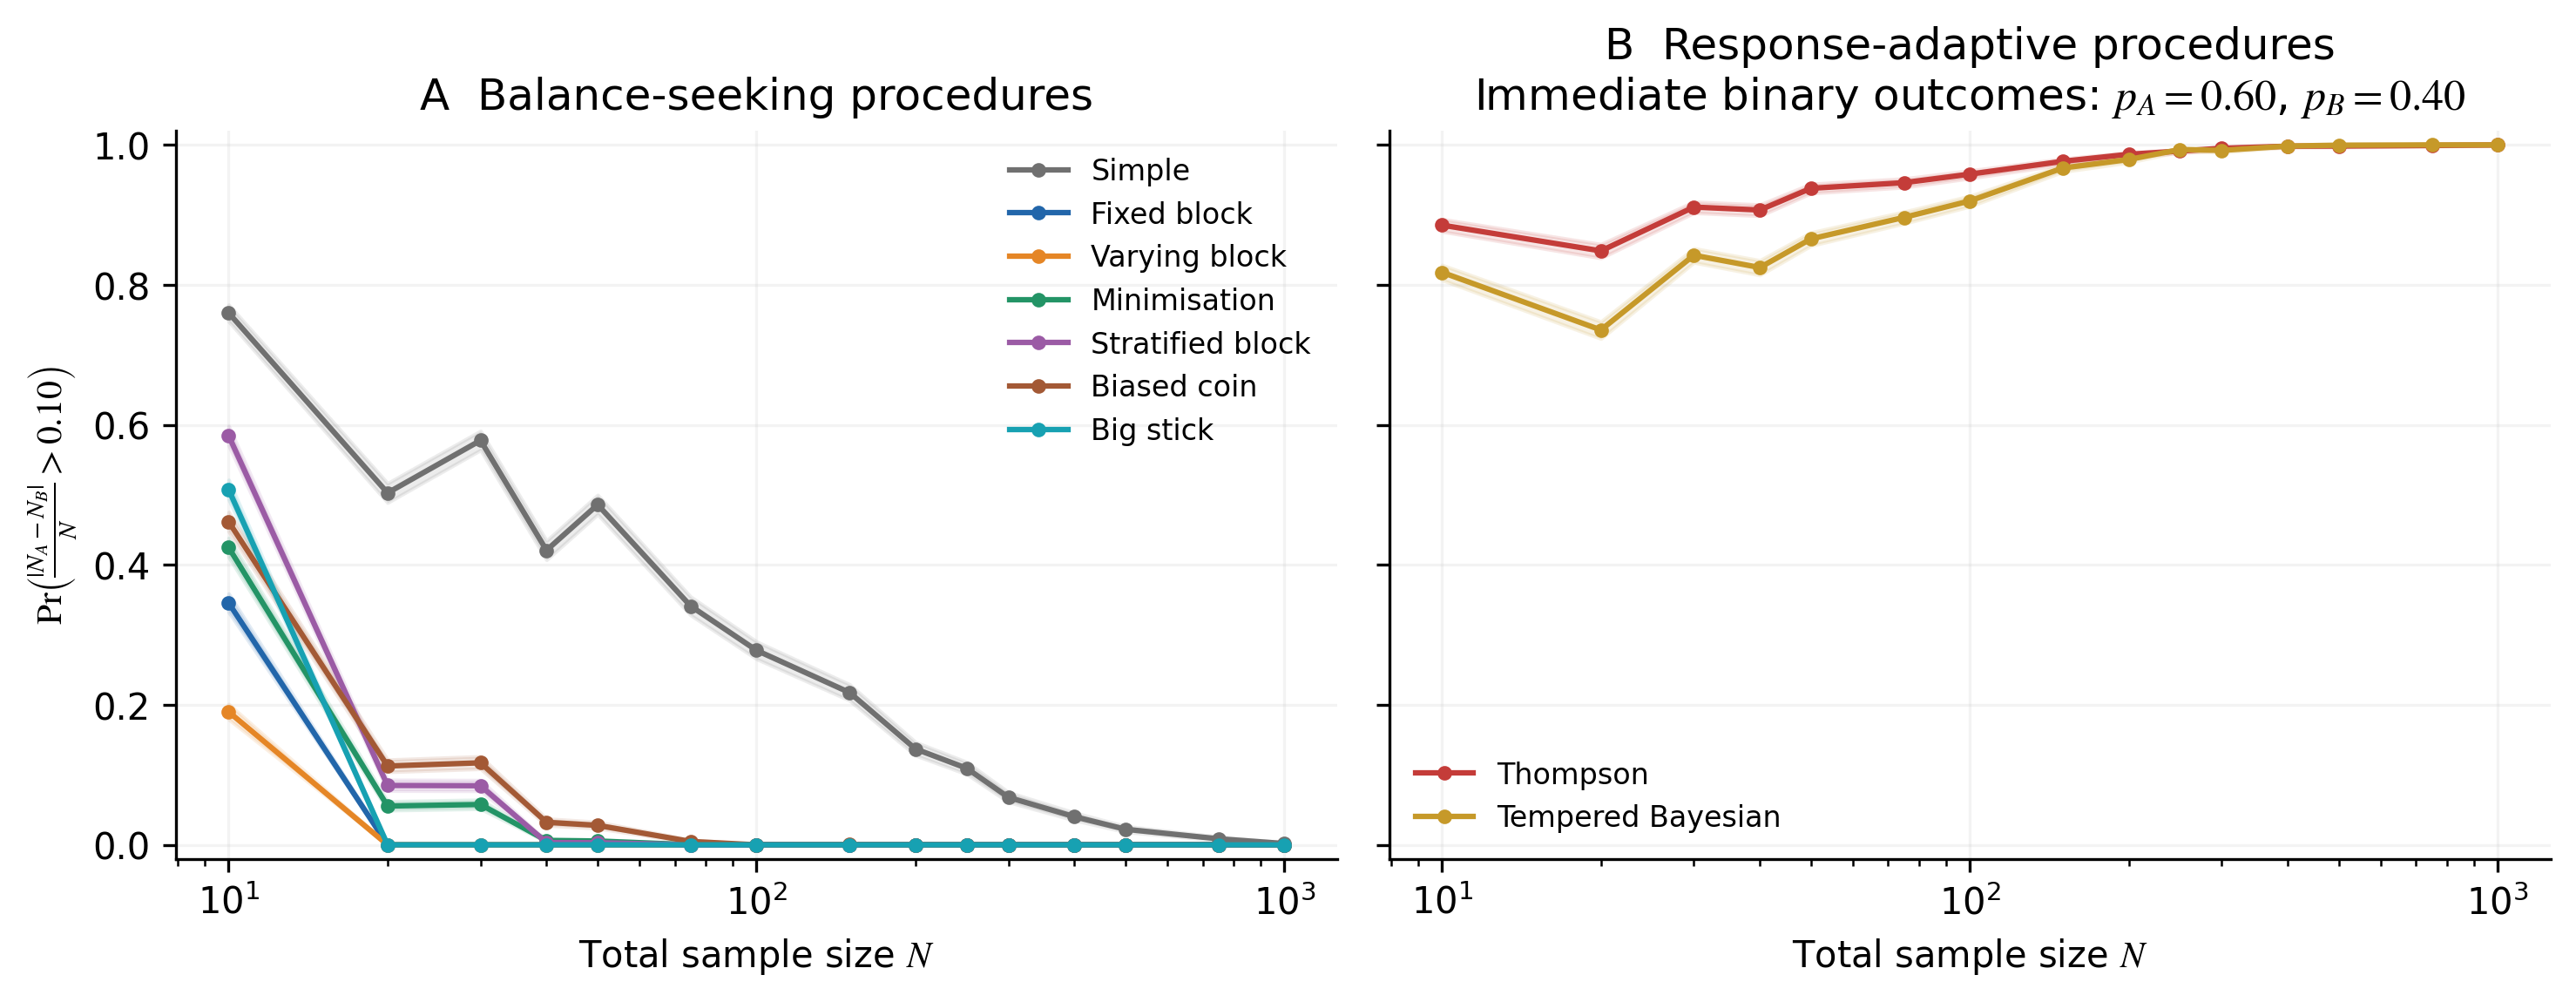

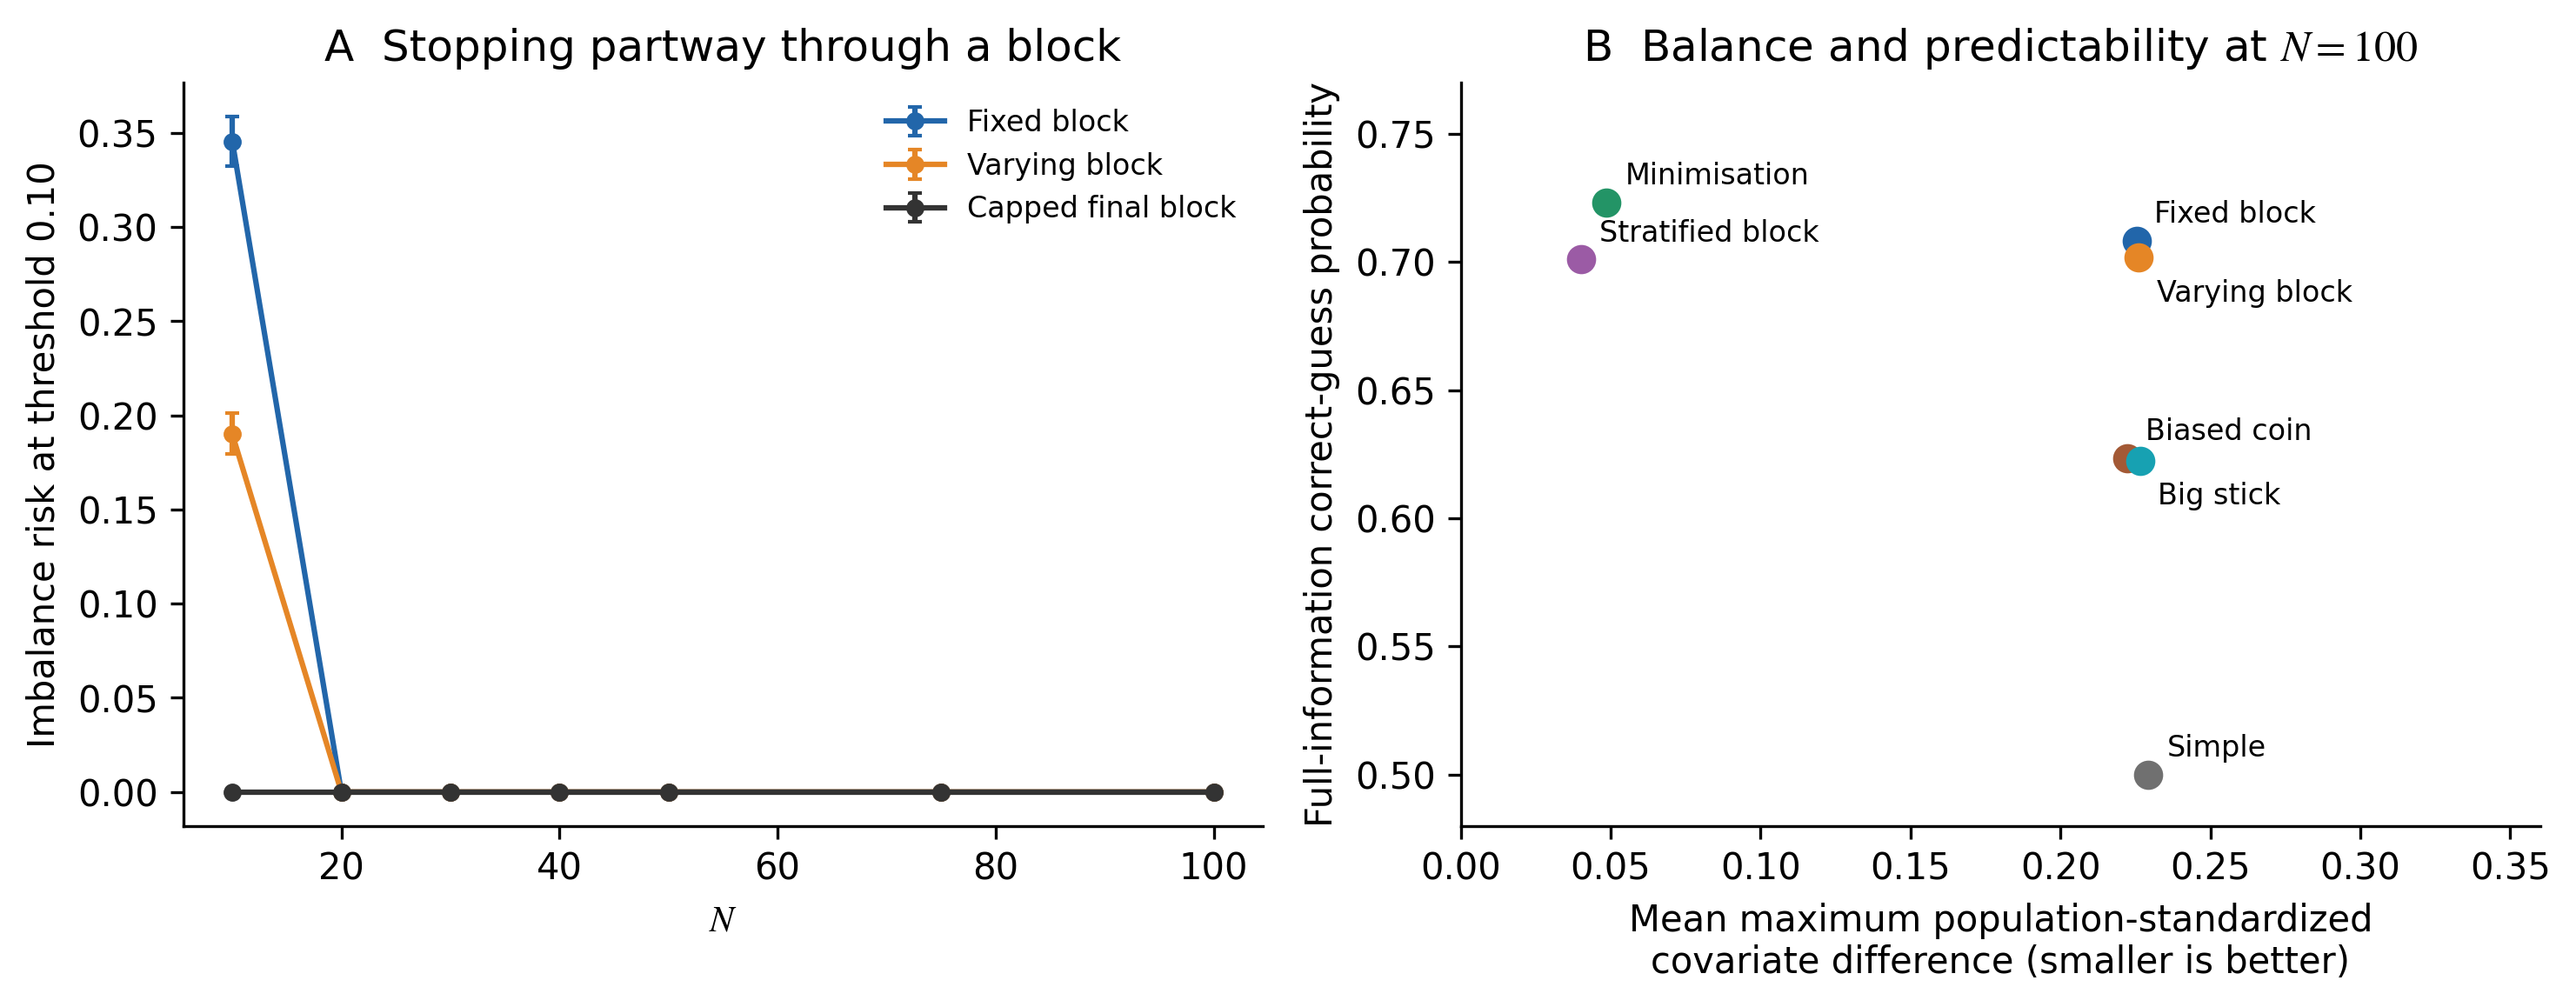

In [5]:
display(Image(filename=str(ROOT/'figures/Figure1_ImbalanceRisk.png'),width=950))
display(Image(filename=str(ROOT/'figures/Figure2_BlocksAndTradeoffs.png'),width=950))

## 4. Conditional stratification limits

The screen requires a pointwise 95% Wilson upper bound at most 0.10 for the chosen difference threshold. Five binary factors generate 32 possible joint strata. Empty strata are valid. The screen concerns allocation counts, rather than clinical safety.

allocation_difference_threshold,0.02,0.10
N,,
20,0,2
30,0,2
50,0,3
100,2,5
300,4,5


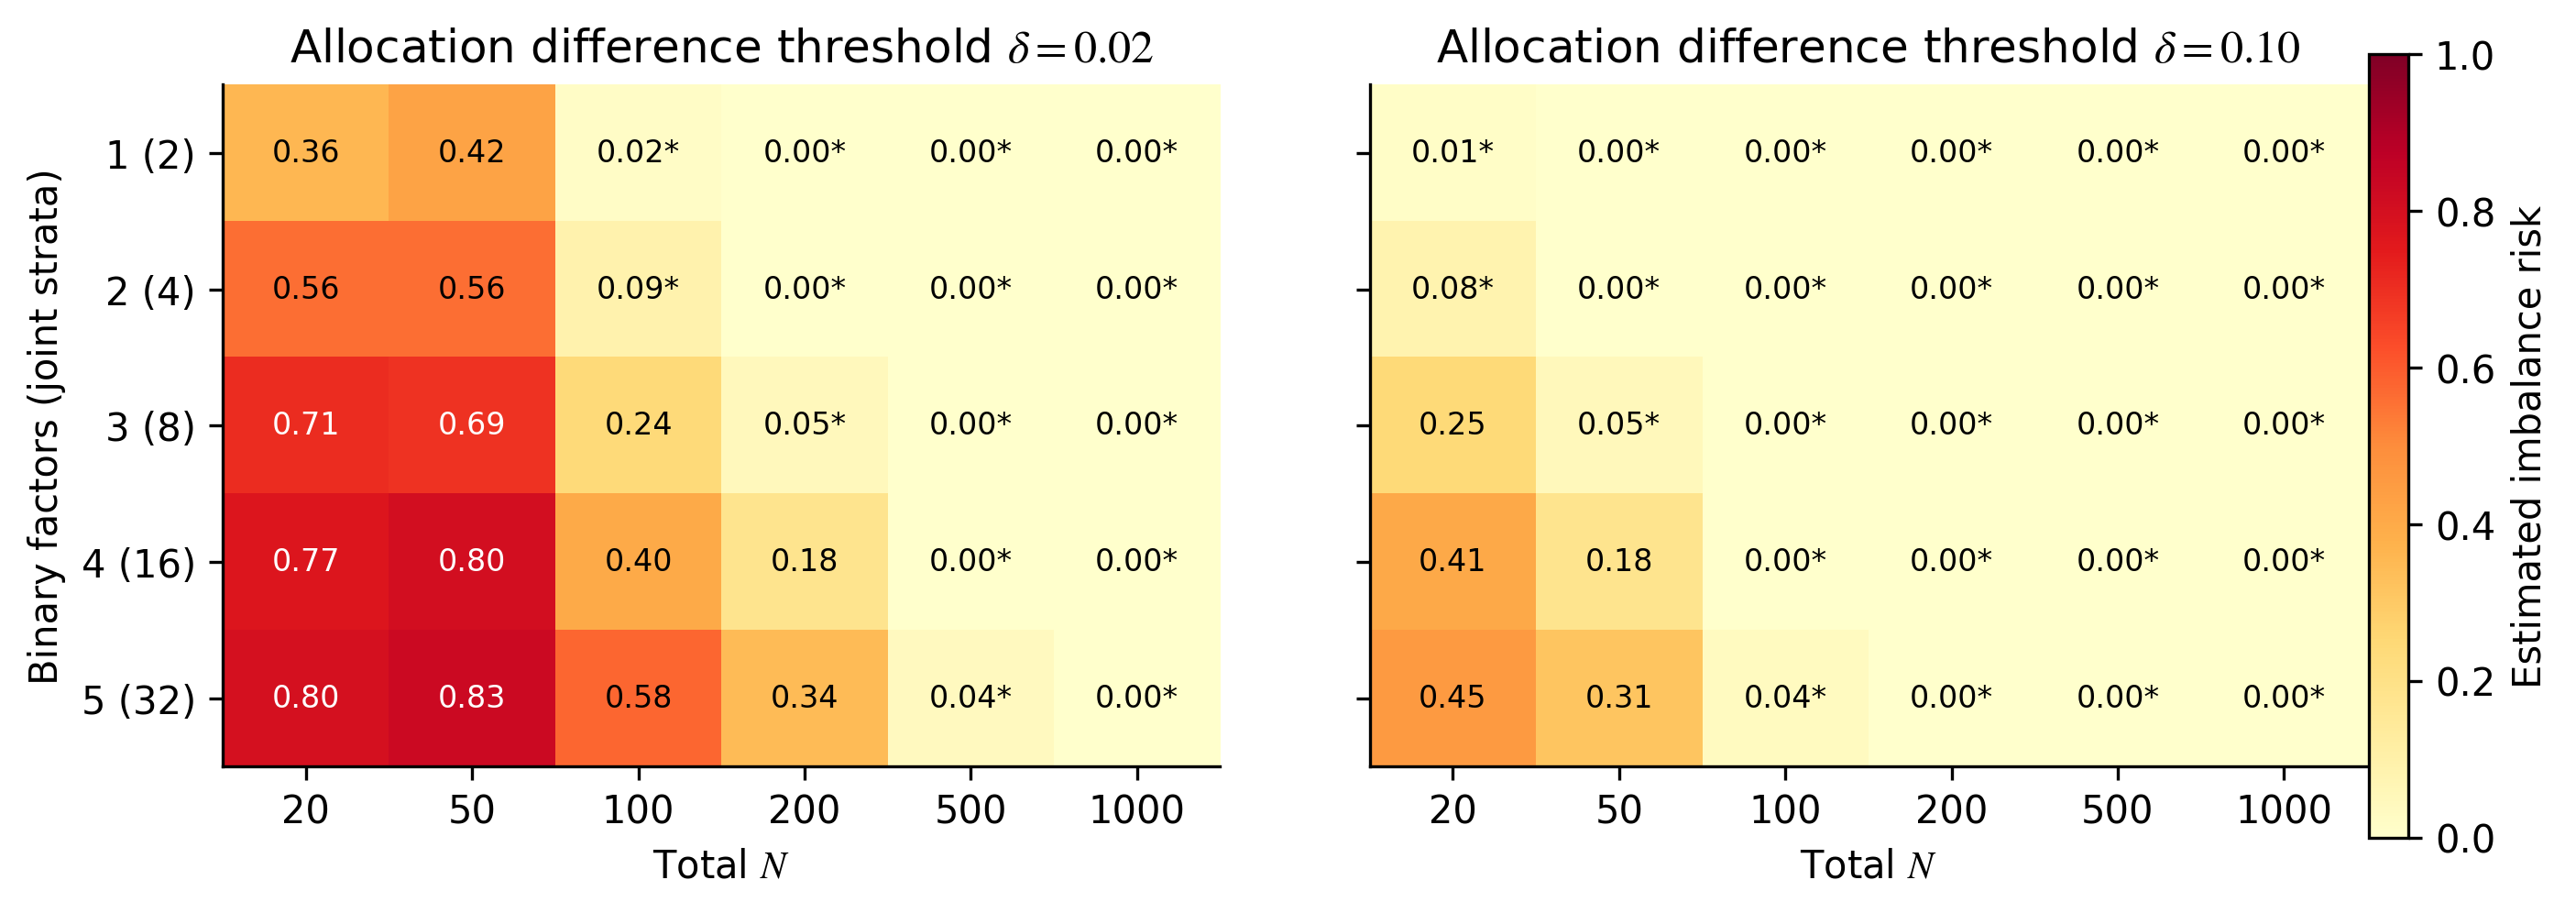

In [6]:
limits=pd.read_csv(ROOT/'results/Table4_StratificationLimits.csv')
z=limits[(limits.profile=='balanced')&(limits.block_size==4)&limits.N.isin([20,30,50,100,300])&limits.allocation_difference_threshold.isin([.02,.10])]
display(z.pivot(index='N',columns='allocation_difference_threshold',values='max_supported_factors'))
display(Image(filename=str(ROOT/'figures/Figure3_StratificationRisk.png'),width=950))

## 5. Prospective prediction and independent simulation validation

All cells at a sample size stay in the same outer fold. Inner tuning is grouped and preprocessing occurs inside each pipeline. Validation uses unseen sample sizes and fresh streams. Family selection uses outer-CV scores. Simpler baselines and unfavourable results are retained.

In [7]:
report=json.loads((ROOT/'results/model_report.json').read_text())
performance=pd.read_csv(ROOT/'results/ModelPerformance.csv')
display(performance.round(4).fillna(''))
print('Selected candidate families:', {k:v['model'] for k,v in report['selected_models'].items()})
print('Exact comparison:', report['exact_probability_baseline'])
print('N=1200 regression:', report['validation']['regression']['N_extrapolation_1200'])

,task,model,stage,accuracy,balanced_accuracy,macro_F1,log_loss,AUC,Brier,R2,MAE,RMSE
0,binary,LogisticRegression,grouped_nested_oof,0.9302,0.6992,0.7562,0.2886,0.8892,0.0589,,,
1,binary,LogisticRegression,independent_simulation_validation,0.9654,0.8559,0.832,0.0875,0.9846,0.0261,,,
2,binary,RandomForest,grouped_nested_oof,0.9298,0.712,0.7639,1.4022,0.7425,0.063,,,
3,binary,RandomForest,independent_simulation_validation,0.9923,0.966,0.9605,0.0574,0.9991,0.0156,,,
4,binary,GradientBoosting,grouped_nested_oof,0.9302,0.7085,0.7624,0.339,0.8145,0.0632,,,
5,binary,GradientBoosting,independent_simulation_validation,0.9904,0.9889,0.9536,0.0338,0.9993,0.0072,,,
6,multiclass,LogisticRegression,grouped_nested_oof,0.8978,0.6701,0.6614,0.2456,,,,,
7,multiclass,LogisticRegression,independent_simulation_validation,0.9295,0.6701,0.6708,0.1536,,,,,
8,multiclass,RandomForest,grouped_nested_oof,0.9053,0.6203,0.68,0.7521,,,,,
9,multiclass,RandomForest,independent_simulation_validation,0.9532,0.7587,0.8147,0.1172,,,,,


Selected candidate families: {'binary': 'LogisticRegression', 'multiclass': 'LogisticRegression', 'regression': 'RandomForest'}
Exact comparison: {'scenarios': 1080, 'coverage_fraction': 0.6923076923076923, 'R2': 0.9990219755967951, 'MAE': 0.0010515936227132028, 'RMSE': 0.0032841715438473957, 'ML_same_subset': {'R2': 0.8899645384191619, 'MAE': 0.013167001851851845, 'RMSE': 0.03483512096375236}}
N=1200 regression: {'scenarios': 260, 'R2': -1325.9305643033483, 'MAE': 0.0008205461538461532, 'RMSE': 0.004717992847354928}


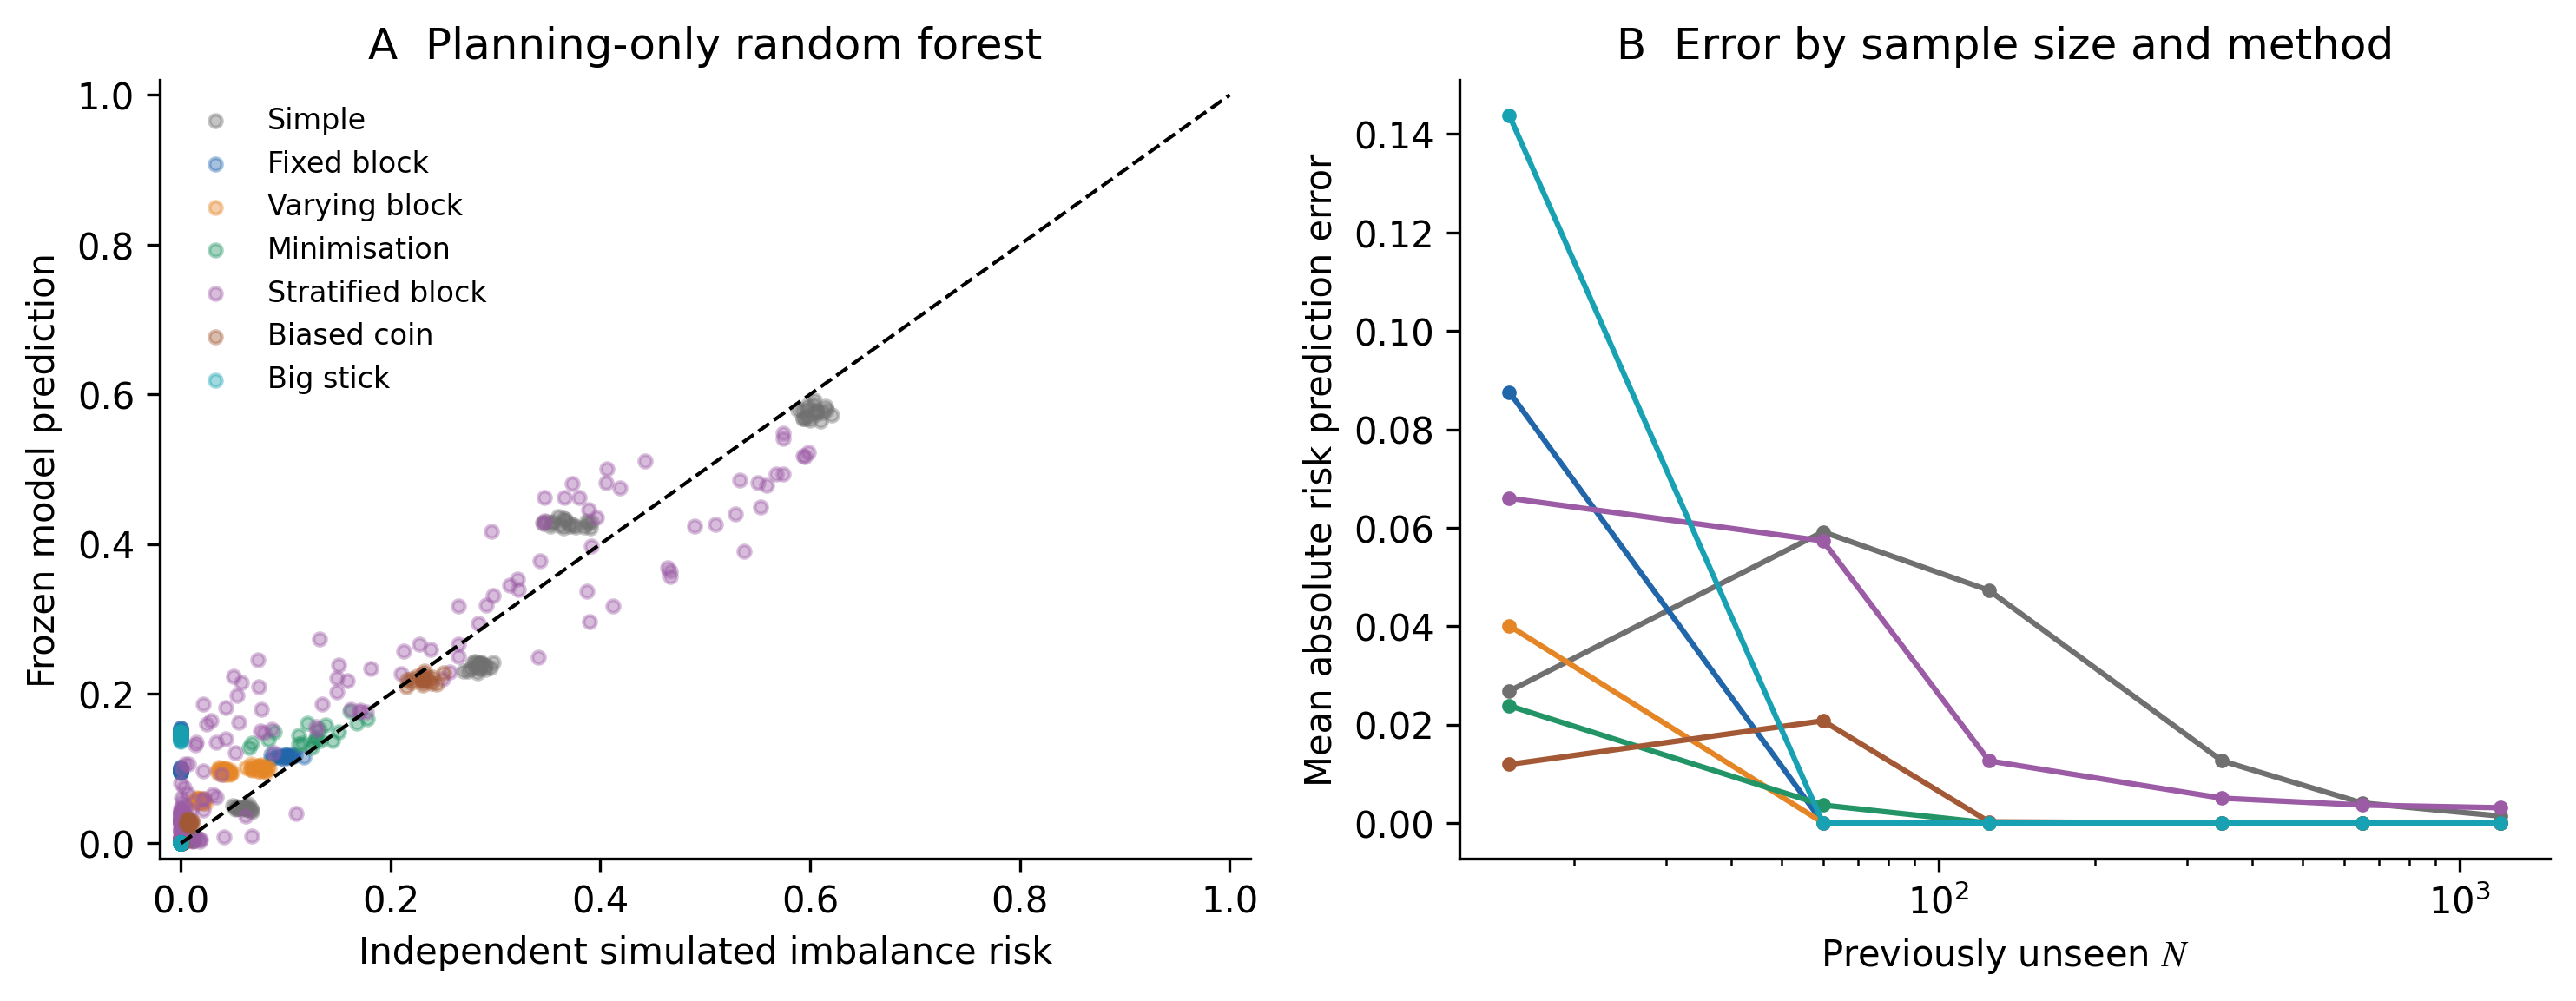

In [8]:
display(Image(filename=str(ROOT/'figures/Figure4_IndependentValidation.png'),width=950))

The selected random forest does not establish an advantage over exact probabilities or the five-neighbour baseline. At $N=1200$, nearly constant risks yield strongly negative $R^2$ despite small absolute error. All binary labels there are low risk, making AUC undefined. Aggregate accuracy alone is insufficient.

## 6. Outcome analysis

The Gaussian substudy compares treatment-only OLS with OLS adjusted for two covariates at $N=30,100,250$. Inferential rates are conditional on estimable fits. Response-adaptive inference remains outside this substudy.

The outcome model is

$$
Y=\tau T+0.8(X_1-p_1)+0.4(X_2-p_2)+\varepsilon,\qquad \varepsilon\sim\mathcal{N}(0,1)
$$

,method,analysis,null_rejection_probability,power_effect_0.4,coverage_95,valid_trials,nonestimable_probability
42,simple,unadjusted,0.0486,0.4370,0.9514,5000,0.0
43,simple,covariate_adjusted,0.0520,0.5072,0.9480,5000,0.0
44,fixed_block,unadjusted,0.0478,0.4476,0.9522,5000,0.0
45,fixed_block,covariate_adjusted,0.0500,0.5022,0.9500,5000,0.0
46,varying_block,unadjusted,0.0526,0.4456,0.9474,5000,0.0
47,varying_block,covariate_adjusted,0.0548,0.5054,0.9452,5000,0.0
48,minimization,unadjusted,0.0332,0.4446,0.9668,5000,0.0
49,minimization,covariate_adjusted,0.0532,0.5204,0.9468,5000,0.0
50,stratified,unadjusted,0.0310,0.4386,0.9690,5000,0.0
51,stratified,covariate_adjusted,0.0472,0.5122,0.9528,5000,0.0


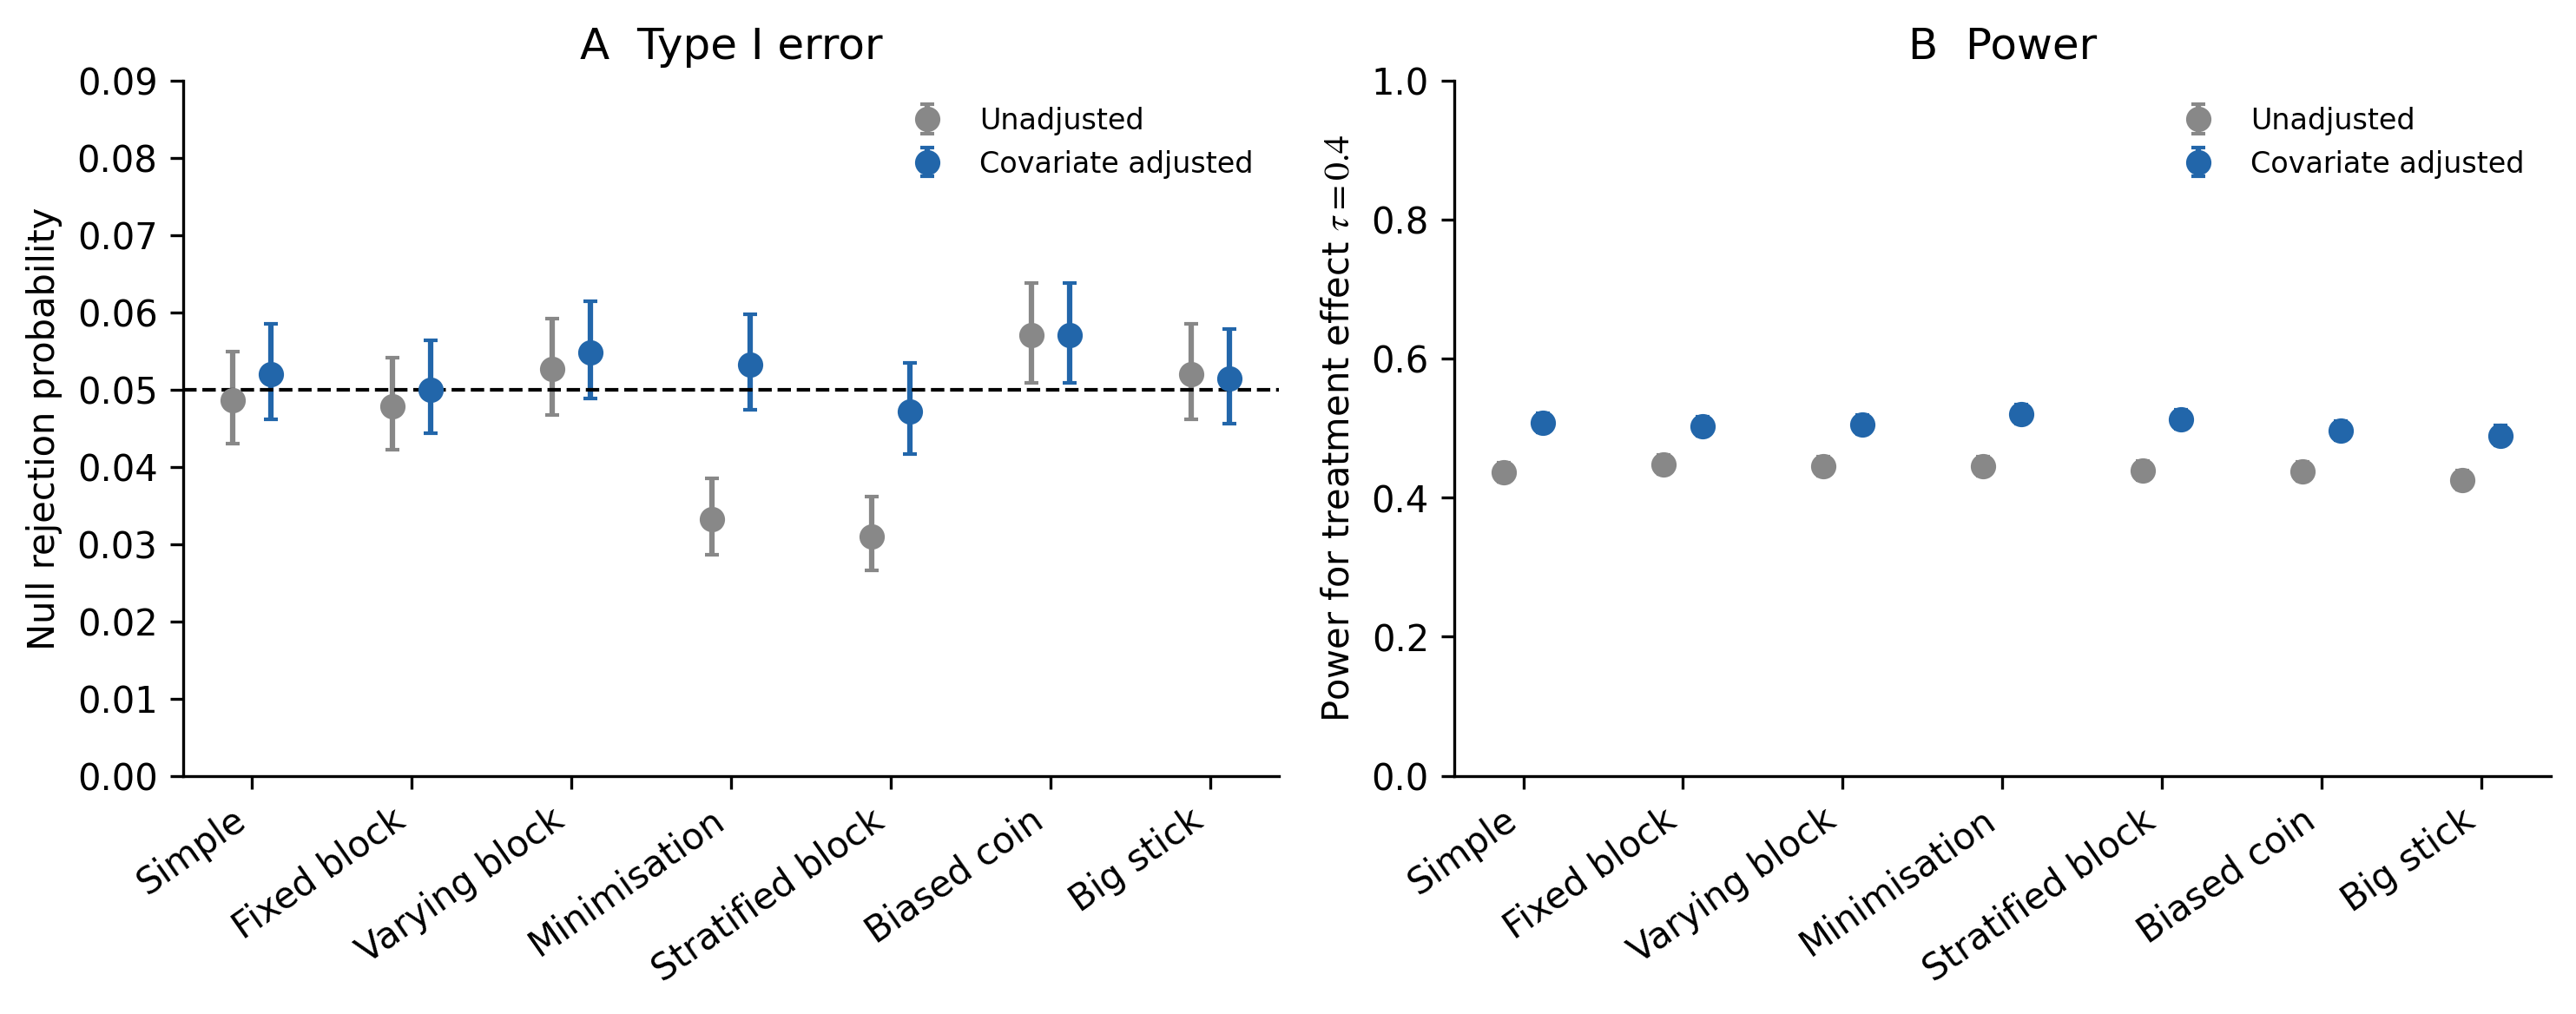

In [9]:
inference=pd.read_csv(ROOT/'results/inference_substudy.csv')
display(inference[(inference.N==100)&(inference.profile=='balanced')][['method','analysis','null_rejection_probability','power_effect_0.4','coverage_95','valid_trials','nonestimable_probability']].round(4))
display(Image(filename=str(ROOT/'figures/Figure5_Inference.png'),width=950))

## 7. Planning comparison tool

Compare seven balance-seeking procedures for one supported scenario. Exact risk takes priority. Simulation adds uncertainty, covariate balance and full-information predictability. Pareto flags use point estimates and do not test ranking uncertainty.

In [10]:
from recommend import compare
example=compare(n=30,n_factors=2,profile='balanced',block_size=4,iterations=5000)
display(example[['method','risk_for_planning','ci_low','ci_high','correct_guess','covariate_difference','planning_risk_source']].round(4))

,method,risk_for_planning,ci_low,ci_high,correct_guess,covariate_difference,planning_risk_source
0,simple,0.5847,0.5709,0.5982,0.5000,0.4194,exact
1,fixed_block,0.0000,0.0000,0.0008,0.7004,0.4112,exact
2,varying_block,0.0000,0.0000,0.0008,0.6988,0.4129,exact
3,minimization,0.0546,0.0486,0.0612,0.7187,0.1644,new Monte Carlo simulation
4,stratified,0.0864,0.0789,0.0945,0.6836,0.1372,new Monte Carlo simulation
5,biased_coin,0.1210,0.1155,0.1338,0.6192,0.4195,exact
6,big_stick,0.0000,0.0000,0.0008,0.6161,0.4168,exact


## 8. Novelty, knowledge gap and limitations

Comparative simulation, minimisation, stratification assessment and tools such as randomizeR already exist. The contribution is a reproducible design-specific comparison exposing terminal-block effects, covariate and predictability trade-offs, one planned outcome analysis, and prospective-surrogate performance against simpler alternatives. The practical gap is how those dimensions jointly inform a specified planning decision. No new allocation algorithm, first-ever comparison or clinical validation is claimed.

Further work should examine richer covariates, independent implementations, delayed adaptive responses and endpoint-specific inference. Algorithm implementations are in randomization_core.py; all experiment settings are in project_config.json.

## 9. Numerical consistency

Recompute all risks and Wilson intervals from raw counts and align saved predictions with fitted pipelines. After execution, validate_project.py --notebook checks saved results, model predictions and notebook execution.

In [11]:
from validate_project import check
validation=check(notebook=False,write=False)
print(json.dumps(validation,indent=2))
assert validation['status']=='passed'

{
  "status": "passed",
  "checks_passed": 43167,
  "simulated_trials": 6660000,
  "scenario_cells": 3948,
  "analytic_checks": 75,
  "notebook_checked": false,
  "python": "3.9.13",
  "simulation_source_sha256": "0d110c0f78a2ecbcdaf440c464aa04f98d04d548e19f30c90bcdaa36d776d0e3"
}
